# Census files, step by step

This notebook walks through the four Census files in `data/census/` using concrete examples. Each step answers one question:

| Step | Question | File |
|---|---|---|
| 1 | How does the Census name places? (FIPS / GEOID) | — |
| 2 | Where is each county? | `cb_2024_us_county_500k.zip` |
| 3 | What is a ZCTA, and how does it relate to a county? | `tab20_zcta520_county20_natl.txt` |
| 4 | How many homes are in each place? | `acsdt5y2024-b25001.dat` |
| 5 | Why is Connecticut special? | `ct_cou_to_cousub_crosswalk.xlsx` |
| 6 | Putting it together: estimating a blank county from ZIP data | all of the above + FHFA |

We follow **Autauga County, Alabama** (`01001`) through most of it.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CENSUS = ROOT / "data" / "census"
FHFA_NEW = ROOT / "data" / "fhfa" / "next_release"
EXAMPLE = "01001"  # Autauga County, AL

## Step 1: How the Census names places

Every place has a numeric code called a **FIPS code**. A county's full ID, its **GEOID**, is

```
  01   001
  │     └── county code, unique only within its state (3 digits)
  └──────── state code (2 digits)
```

So `01001` is state `01` (Alabama), county `001` (Autauga). The codes are **text, not numbers**: read as numbers, `01001` becomes `1001` and no longer matches anything. That's why every file here is read with `dtype=str`.

States are numbered roughly alphabetically, with gaps:

In [2]:
states = pd.DataFrame({
    "STATEFP": ["01", "02", "06", "09", "11", "48", "72"],
    "state": ["Alabama", "Alaska", "California", "Connecticut", "District of Columbia", "Texas", "Puerto Rico (territory)"],
})
states

,STATEFP,state
0,01,Alabama
1,02,Alaska
2,06,California
3,09,Connecticut
4,11,District of Columbia
5,48,Texas
6,72,Puerto Rico (territory)


Territories (`60` American Samoa, `66` Guam, `69` Northern Marianas, `72` Puerto Rico, `78` Virgin Islands) appear in Census files but are **out of scope** for our layer: 50 states + DC only.

## Step 2: County boundaries, *where* each county is

`cb_2024_us_county_500k.zip` is a **shapefile**: a table with one row per county plus a polygon outline for each.
- *cb* = "cartographic boundary": coastlines are trimmed to the shoreline so maps look right.
- *500k* = drawn at 1:500,000 scale, a medium level of detail.
- *2024* = the county list as of 2024.

In [3]:
counties_all = gpd.read_file(CENSUS / "cb_2024_us_county_500k.zip")
print("rows (counties incl. territories):", len(counties_all))
print("coordinate system:", counties_all.crs, "(NAD83 longitude/latitude)")
counties_all[counties_all.GEOID == EXAMPLE].drop(columns="geometry").T

rows (counties incl. territories): 3235
coordinate system: EPSG:4269 (NAD83 longitude/latitude)


,808
STATEFP,01
COUNTYFP,001
COUNTYNS,00161526
GEOIDFQ,0500000US01001
GEOID,01001
NAME,Autauga
NAMELSAD,Autauga County
STUSPS,AL
STATE_NAME,Alabama
LSAD,06


The columns we need for the layer:

| Column | Example | Layer property |
|---|---|---|
| `GEOID` | `01001` | `geoid` |
| `NAMELSAD` | `Autauga County` (name **with** its suffix) | `name` |
| `STUSPS` | `AL` | `state` |

`NAME` is the bare name. The suffix varies: *County*, *Parish* (LA), *Borough* / *Census Area* (AK), *city* (independent cities in VA and elsewhere), *Planning Region* (CT), and *Municipio* (Puerto Rico, a territory dropped below). A few names have no suffix (e.g. *District of Columbia*).

In [4]:
counties_all["suffix"] = [full[len(short):].strip() for full, short in zip(counties_all.NAMELSAD, counties_all.NAME)]
counties_all.suffix.value_counts()

suffix
County              2999
Municipio             78
Parish                64
city                  40
Borough               13
Census Area           11
Planning Region        9
Municipality           6
                       5
City and Borough       4
District               3
Island                 3
Name: count, dtype: int64

In [5]:
TERRITORIES = {"60", "66", "69", "72", "78"}
counties = counties_all[~counties_all.STATEFP.isin(TERRITORIES)].copy()
print("counties in 50 states + DC:", len(counties))

counties in 50 states + DC: 3144


Here is Alabama, with Autauga highlighted:

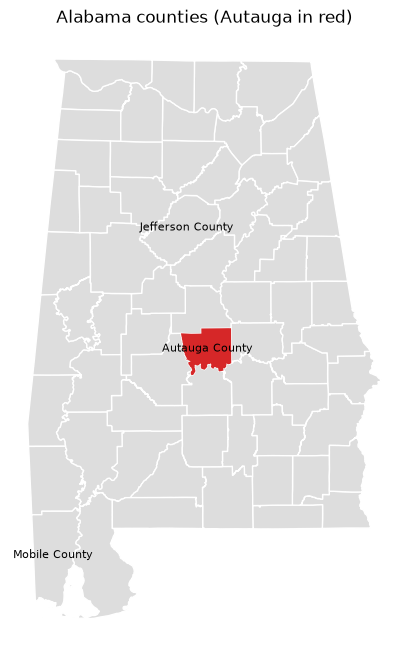

In [6]:
al = counties[counties.STUSPS == "AL"]
ax = al.plot(color="#ddd", edgecolor="white", figsize=(6, 8))
al[al.GEOID == EXAMPLE].plot(ax=ax, color="tab:red")
for _, row in al[al.GEOID.isin([EXAMPLE, "01073", "01097"])].iterrows():
    p = row.geometry.representative_point()
    ax.annotate(row.NAMELSAD, (p.x, p.y), ha="center", fontsize=8)
ax.set_axis_off(); ax.set_title("Alabama counties (Autauga in red)");

## Step 3: ZCTAs and how they overlap counties

FHFA publishes house price indexes for **ZIP codes** too. ZIP codes, however, aren't areas: they're **mail delivery routes**, and some are a single building or a PO box.

The Census therefore draws **ZCTAs** (*ZIP Code Tabulation Areas*): polygons that approximate the area each ZIP serves. A ZCTA usually has the same 5 digits as its ZIP.

The catch: **ZCTAs don't follow county lines.** One ZCTA can straddle 2, 3 or more counties. The relationship file records every overlap:

In [7]:
rel = pd.read_csv(CENSUS / "tab20_zcta520_county20_natl.txt", sep="|", dtype=str, encoding="utf-8-sig")
for c in ["AREALAND_PART", "AREALAND_ZCTA5_20", "AREALAND_COUNTY_20"]:
    rel[c] = pd.to_numeric(rel[c])
rel = rel.rename(columns={"GEOID_ZCTA5_20": "zcta", "GEOID_COUNTY_20": "county", "NAMELSAD_COUNTY_20": "county_name",
                          "AREALAND_ZCTA5_20": "zcta_land", "AREALAND_COUNTY_20": "county_land", "AREALAND_PART": "part_land"})
rel = rel[["zcta", "county", "county_name", "zcta_land", "county_land", "part_land"]]
print("rows:", len(rel))
rel.dropna(subset=["zcta"]).head()

rows: 47863


,zcta,county,county_name,zcta_land,county_land,part_land
903,00601,72001,Adjuntas Municipio,166847909.0,172725726,164781682
904,00601,72141,Utuado Municipio,166847909.0,294045395,2066227
905,00602,72003,Aguada Municipio,78546713.0,79923637,78530159
906,00602,72011,Añasco Municipio,78546713.0,101747429,16554
907,00603,72005,Aguadilla Municipio,88957333.0,94618010,88747846


Each row is **one piece**: the land where a given ZCTA and a given county overlap. `part_land` is that piece's land area in m².

Here are all the ZCTAs that touch Autauga County:

In [8]:
auto = rel[rel.county == EXAMPLE].dropna(subset=["zcta"]).copy()
auto["share_of_zcta_in_autauga"] = auto.part_land / auto.zcta_land
auto["share_of_autauga"] = auto.part_land / auto.county_land
auto.sort_values("share_of_autauga", ascending=False).round(3)

,zcta,county,county_name,zcta_land,county_land,part_land,share_of_zcta_in_autauga,share_of_autauga
16124,36067,01001,Autauga County,632832373.0,1539634184,632832373,1.000,0.411
16048,36003,01001,Autauga County,212198964.0,1539634184,212198964,1.000,0.138
16052,36006,01001,Autauga County,199507097.0,1539634184,150800198,0.756,0.098
16433,36749,01001,Autauga County,159897291.0,1539634184,133567101,0.835,0.087
16065,36022,01001,Autauga County,232869355.0,1539634184,104664820,0.449,0.068
16111,36051,01001,Autauga County,135070976.0,1539634184,87097470,0.645,0.057
16411,36703,01001,Autauga County,323371731.0,1539634184,82342383,0.255,0.053
16445,36758,01001,Autauga County,206327883.0,1539634184,63994229,0.310,0.042
16122,36066,01001,Autauga County,52112156.0,1539634184,37005464,0.710,0.024
16144,36091,01001,Autauga County,216129176.0,1539634184,32847913,0.152,0.021


How to read this:
- `share_of_autauga` says how much of Autauga's land each ZCTA covers. These add up to about 1.
- `share_of_zcta_in_autauga` below 1 means that ZCTA **also extends into other counties**.

Take the ZCTA that straddles the most counties:

In [9]:
straddler = (rel[rel.zcta.isin(auto.zcta)].groupby("zcta").county.nunique().idxmax())
pieces = rel[rel.zcta == straddler].copy()
pieces["share_of_zcta"] = pieces.part_land / pieces.zcta_land
print(f"ZCTA {straddler} is split across {len(pieces)} counties:")
pieces[["zcta", "county", "county_name", "part_land", "share_of_zcta"]].round(3)

ZCTA 36051 is split across 3 counties:


,zcta,county,county_name,part_land,share_of_zcta
16111,36051,01001,Autauga County,87097470,0.645
16112,36051,01021,Chilton County,20829176,0.154
16113,36051,01051,Elmore County,27144330,0.201


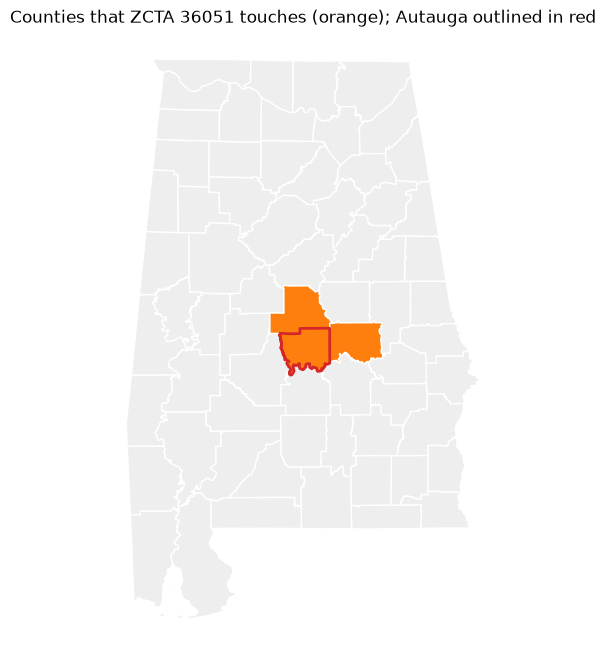

In [10]:
ax = al.plot(color="#eee", edgecolor="white", figsize=(6, 8))
al[al.GEOID.isin(pieces.county)].plot(ax=ax, color="tab:orange", edgecolor="white")
al[al.GEOID == EXAMPLE].boundary.plot(ax=ax, color="tab:red", linewidth=2)
ax.set_axis_off(); ax.set_title(f"Counties that ZCTA {straddler} touches (orange); Autauga outlined in red");

If ZIP `{straddler}` has a house price index, it tells us something about **several** counties. To use ZIP data for a county, we need to know **how much of each ZIP lies in that county**. Land area is one answer. Housing units, next step, is a better one, since price indexes are about homes, not acres.

Two more things about this file:

In [11]:
per_zcta = rel.dropna(subset=["zcta"]).groupby("zcta").county.nunique()
print("ZCTAs:", len(per_zcta))
print("ZCTAs in exactly 1 county:", (per_zcta == 1).sum(), "| in 2+ counties:", (per_zcta > 1).sum())
print("rows with no ZCTA (county land that no ZCTA covers, e.g. wilderness):", rel.zcta.isna().sum())

ZCTAs: 33791
ZCTAs in exactly 1 county: 23605 | in 2+ counties: 10186
rows with no ZCTA (county land that no ZCTA covers, e.g. wilderness): 903


It's the **2020** version, so it uses county codes from 2020, including Connecticut's old counties (see Step 5).

## Step 4: ACS housing units, *how many homes* are in each place

The **American Community Survey (ACS)** is the Census Bureau's continuous survey of about 3.5 million households a year. Small places get few responses per year, so the Census pools **5 years** (here 2020–2024) for stable estimates.

Each ACS *table* answers one question. **B25001 = "How many housing units are there?"** (houses, apartments, mobile homes, occupied or vacant).

The file covers *every kind of geography* (nation, states, counties, tracts, ZCTAs, school districts, …) in a single file:

In [12]:
acs = pd.read_csv(CENSUS / "acsdt5y2024-b25001.dat", sep="|", dtype=str)
print("rows:", len(acs))
acs.head()

rows:

 616690


,GEO_ID,B25001_E001,B25001_M001
0,0100000US,143775355,10234
1,0100089US,449991,4506
2,0100090US,630,146
3,0100091US,1161373,1437
4,0100092US,32283,441


The columns:
- `B25001_E001`: the **E**stimate (number of housing units)
- `B25001_M001`: the **M**argin of error (90% confidence). Small places have relatively large margins.

`GEO_ID` packs the geography type and the code together:

```
 050 00 00 US 01001
 │            └── the place's own code (here: county GEOID)
 └─────────────── "summary level" = what kind of place
                  050 = county, 860 = ZCTA, 040 = state, 140 = census tract ...
```

In [13]:
acs["sumlevel"] = acs.GEO_ID.str[:3]
acs["code"] = acs.GEO_ID.str.split("US").str[-1]
acs["housing_units"] = pd.to_numeric(acs.B25001_E001)
acs["moe"] = pd.to_numeric(acs.B25001_M001)

labels = {"010": "nation", "040": "state", "050": "county", "140": "census tract", "150": "block group", "860": "ZCTA"}
(acs[acs.sumlevel.isin(labels)].assign(kind=lambda a: a.sumlevel.map(labels))
    .groupby(["sumlevel", "kind"]).size().rename("rows"))

sumlevel  kind        
010       nation              19
040       state              603
050       county            3222
140       census tract     85382
150       block group     242297
860       ZCTA             33772
Name: rows, dtype: int64

Autauga County, and the state of Alabama for comparison:

In [14]:
acs[acs.GEO_ID.isin(["0500000US01001", "0400000US01"])][["GEO_ID", "sumlevel", "code", "housing_units", "moe"]]

,GEO_ID,sumlevel,code,housing_units,moe
175,0400000US01,040,01,2337265,430
778,0500000US01001,050,01001,25039,34


Autauga has about 25,000 housing units, ± a few dozen.

Now the ZCTA rows. Here are the ZCTAs that touch Autauga, with their housing units:

In [15]:
hu_zcta = acs.loc[acs.sumlevel == "860", ["code", "housing_units", "moe"]].rename(columns={"code": "zcta"})
auto_hu = auto.merge(hu_zcta, on="zcta", how="left")
auto_hu[["zcta", "share_of_zcta_in_autauga", "housing_units", "moe"]].round(3)

,zcta,share_of_zcta_in_autauga,housing_units,moe
0,36003,1.000,961,222
1,36006,0.756,920,255
2,36008,1.000,0,13
3,36022,0.449,6041,458
4,36051,0.645,1144,291
5,36066,0.710,9245,498
6,36067,1.000,11900,519
7,36091,0.152,1794,242
8,36703,0.255,5620,434
9,36749,0.835,434,147


### Splitting a ZCTA's homes between counties

The ACS counts homes **per whole ZCTA**, not per piece. A simple approximation is to assume homes are spread evenly over a ZCTA's land:

> homes in piece ≈ ZCTA housing units × (piece land ÷ ZCTA land)

It's an approximation (homes cluster in towns), but we can check it: summing the pieces inside Autauga should land near the county's own ACS total.

In [16]:
auto_hu["est_units_in_autauga"] = auto_hu.housing_units * auto_hu.share_of_zcta_in_autauga
county_total = acs.loc[acs.GEO_ID == "0500000US01001", "housing_units"].item()
print(f"sum of ZCTA pieces: {auto_hu.est_units_in_autauga.sum():,.0f}   county's own ACS total: {county_total:,.0f}")

sum of ZCTA pieces: 25,822   county's own ACS total: 25,039


Same check for every county in the country:

count    3213.000
mean        1.067
std         0.498
min         0.031
5%          0.842
25%         0.967
50%         1.001
75%         1.056
95%         1.409
max        13.121
Name: ratio, dtype: float64


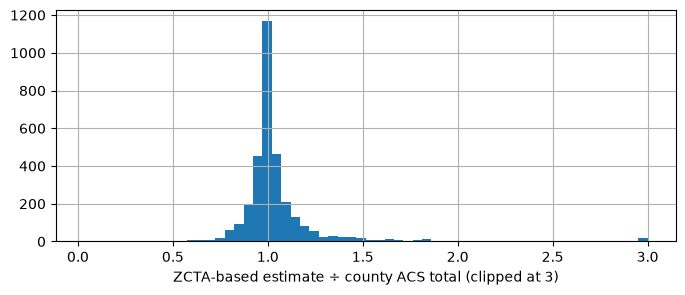

In [17]:
pieces_all = rel.dropna(subset=["zcta"]).merge(hu_zcta, on="zcta")
pieces_all["est_units"] = pieces_all.housing_units * pieces_all.part_land / pieces_all.zcta_land
hu_county = acs.loc[acs.sumlevel == "050", ["code", "housing_units"]].rename(columns={"code": "county"})
check = pieces_all.groupby("county").est_units.sum().rename("from_zctas").to_frame().join(
    hu_county.set_index("county").housing_units.rename("county_acs"), how="inner")
check["ratio"] = check.from_zctas / check.county_acs
print(check.ratio.describe(percentiles=[.05, .25, .5, .75, .95]).round(3))
ax = check.ratio.clip(0, 3).hist(bins=60, figsize=(8, 3)); ax.set_xlabel("ZCTA-based estimate ÷ county ACS total (clipped at 3)");

The typical county comes out close to 1, but the tails are wide. That's how good (and bad) the "spread evenly over land" assumption is, which is worth knowing before we use it for weights.

## Step 5: Connecticut

In 2022 Connecticut's 8 counties were replaced, for statistical purposes, by **9 planning regions** with *different borders*. Files from before and after the change disagree:

| File | Connecticut uses |
|---|---|
| County boundaries 2024 | 9 planning regions (`09110`–`09190`) |
| ACS 2020–2024 | 9 planning regions |
| FHFA next release | 9 planning regions |
| FHFA old release | 8 old counties (`09001`–`09015`) |
| ZCTA relationship file 2020 | 8 old counties |

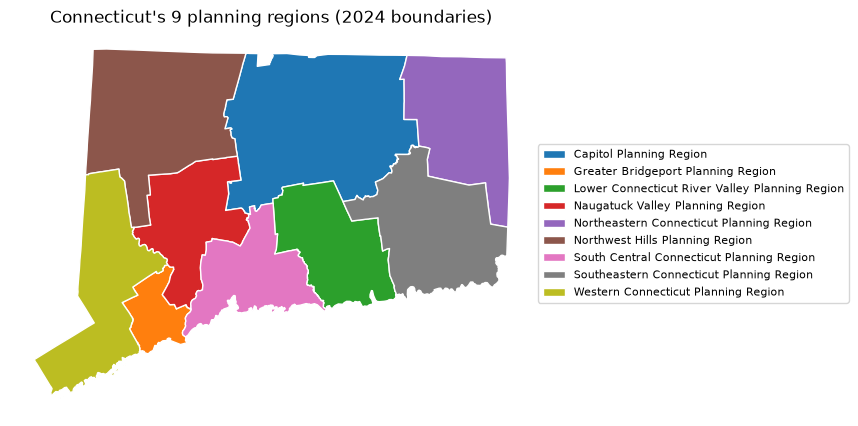

In [18]:
ct_now = counties[counties.STATEFP == "09"]
ax = ct_now.plot(column="NAMELSAD", cmap="tab10", edgecolor="white", figsize=(9, 5), legend=True,
                 legend_kwds={"loc": "center left", "bbox_to_anchor": (1, .5), "fontsize": 8})
ax.set_axis_off(); ax.set_title("Connecticut's 9 planning regions (2024 boundaries)");

The crosswalk lists each Connecticut **town** (the building block of both systems) with its old county and its new region:

In [19]:
ct = pd.read_excel(CENSUS / "ct_cou_to_cousub_crosswalk.xlsx", dtype=str)
ct.columns = [c.split("\n")[0] for c in ct.columns]
ct = ct[ct.COUSUBFP != "00000"]  # drop the 'County subdivisions not defined' placeholder rows
ct[["COUSUB_NAMELSAD", "OLD_COUNTY_NAMELSAD", "NEW_COUNTY_NAMELSAD"]].head(10)

,COUSUB_NAMELSAD,OLD_COUNTY_NAMELSAD,NEW_COUNTY_NAMELSAD
0,Bridgeport town,Fairfield County,Greater Bridgeport Planning Region
1,Easton town,Fairfield County,Greater Bridgeport Planning Region
2,Fairfield town,Fairfield County,Greater Bridgeport Planning Region
3,Monroe town,Fairfield County,Greater Bridgeport Planning Region
4,Stratford town,Fairfield County,Greater Bridgeport Planning Region
5,Trumbull town,Fairfield County,Greater Bridgeport Planning Region
7,Shelton town,Fairfield County,Naugatuck Valley Planning Region
9,Norwalk town,Fairfield County,Western Connecticut Planning Region
10,Bethel town,Fairfield County,Western Connecticut Planning Region
11,Brookfield town,Fairfield County,Western Connecticut Planning Region


In [20]:
pd.crosstab(ct.OLD_COUNTY_NAMELSAD, ct.NEW_COUNTY_NAMELSAD.str.replace(" Planning Region", ""),
            margins=True, margins_name="towns")

NEW_COUNTY_NAMELSAD,Capitol,Greater Bridgeport,Lower Connecticut River Valley,Naugatuck Valley,Northeastern Connecticut,Northwest Hills,South Central Connecticut,Southeastern Connecticut,Western Connecticut,towns
OLD_COUNTY_NAMELSAD,,,,,,,,,,
Fairfield County,0,6,0,1,0,0,0,0,16,23
Hartford County,26,0,0,1,0,2,0,0,0,29
Litchfield County,0,0,0,5,0,19,0,0,2,26
Middlesex County,0,0,15,0,0,0,0,0,0,15
New Haven County,0,0,0,12,0,0,15,0,0,27
New London County,0,0,2,0,1,0,0,18,0,21
Tolland County,12,0,0,0,1,0,0,0,0,13
Windham County,0,0,0,0,14,0,0,1,0,15
towns,38,6,17,19,16,21,15,19,18,169


Read across a row: e.g. Fairfield County's towns ended up in **several** regions. Down a column, most regions take towns from **several** old counties. Because the mapping is many-to-many, an old-county number can't simply be relabelled as a region number. That's why old-release Connecticut needs a deliberate decision, and a note in `NOTES.md`.

## Step 6: Putting it together, a blank county estimated from ZIPs

This is the idea behind Part 2. Take a county where FHFA publishes **no** county index, but some of its ZIPs **do** have an index:

1. Find the ZCTAs that overlap the county (Step 3).
2. Estimate how many homes of each ZCTA lie in the county (Step 4).
3. Keep the ZCTAs whose ZIP has an FHFA value.
4. Take a housing-unit-weighted average of their price changes.

In [21]:
def read_fhfa(path, key_col, key):
    df = pd.read_excel(path, skiprows=5, usecols=range(6) if key == "zip" else None, dtype={key_col: str})
    return df.rename(columns={key_col: key, "Year": "year", "HPI": "hpi"})[[key, "year", "hpi"]]

cty = read_fhfa(FHFA_NEW / "hpi_at_county.xlsx", "FIPS code", "fips")
zp = read_fhfa(FHFA_NEW / "hpi_at_zip5.xlsx", "Five-Digit ZIP Code", "zip")
L = cty.year.max()

def yoy(df, key):
    w = df[df.year.isin([L - 1, L])].pivot(index=key, columns="year", values="hpi")
    return ((w[L] / w[L - 1] - 1) * 100).dropna().rename("yoy_pct")

county_yoy, zip_yoy = yoy(cty, "fips"), yoy(zp, "zip")
print(f"latest year {L}: {len(county_yoy)} counties and {len(zip_yoy)} ZIPs have a YoY value")

latest year 2025: 2612 counties and 14731 ZIPs have a YoY value


In [22]:
pieces_all = pieces_all.join(zip_yoy, on="zcta")
blank = pieces_all[~pieces_all.county.isin(county_yoy.index) & pieces_all.county.isin(counties.GEOID)]
# pick the blank county with the most homes covered by ZIPs that have data
cover = blank.dropna(subset=["yoy_pct"]).groupby("county").est_units.sum()
target = cover.idxmax()
name = counties.set_index("GEOID").loc[target, ["NAMELSAD", "STUSPS"]]
print(f"example blank county: {target} {name.NAMELSAD}, {name.STUSPS}")

example blank county: 48229 Hudspeth County, TX


In [23]:
t = blank[blank.county == target][["zcta", "housing_units", "part_land", "zcta_land", "est_units", "yoy_pct"]].copy()
t["has_zip_hpi"] = t.yoy_pct.notna()
t.sort_values("est_units", ascending=False).round(2)

,zcta,housing_units,part_land,zcta_land,est_units,yoy_pct,has_zip_hpi
40594,79938,30376,460372031,1.010715e+09,13836.01,-0.12,True
40552,79839,430,845977075,8.459771e+08,430.00,NaN,False
40567,79855,1053,327423322,1.184220e+09,291.14,NaN,False
40561,79851,217,1140391557,1.140392e+09,217.00,NaN,False
40558,79847,124,981411763,2.153524e+09,56.51,NaN,False
40550,79837,191,515862567,2.816586e+09,34.98,NaN,False


In [24]:
used = t[t.has_zip_hpi]
estimate = (used.yoy_pct * used.est_units).sum() / used.est_units.sum()
coverage = used.est_units.sum() / t.est_units.sum()
print(f"estimated {L} YoY for {name.NAMELSAD}: {estimate:.2f}%")
print(f"based on {len(used)} ZIPs covering {coverage:.0%} of the county's homes")

estimated 2025 YoY for Hudspeth County: -0.12%
based on 1 ZIPs covering 93% of the county's homes


### Sanity check: does that add up?

Compare the homes we *think* are in the county with the county's own ACS total from Step 4:

In [25]:
county_hu = hu_county.set_index("county").housing_units
print(f"homes in {name.NAMELSAD} by our ZCTA estimate: {t.est_units.sum():,.0f}")
print(f"homes in {name.NAMELSAD} per ACS county table:  {county_hu[target]:,.0f}")

homes in Hudspeth County by our ZCTA estimate: 14,866
homes in Hudspeth County per ACS county table:  1,133


Way off. ZCTA `79938` is mostly suburban **El Paso**: its ~30,000 homes sit at the El Paso end, but the ZCTA's land stretches far into empty Hudspeth County. "Spread homes evenly over land" therefore hands Hudspeth thousands of El Paso homes, and the "estimate" is really El Paso's price change.

**Lesson:** land-area allocation breaks down when a ZCTA mixes a city and empty land. Two guards:
- Check the allocated total against the county's ACS total and cap or flag mismatches.
- Measure coverage against the **county's ACS homes**, not against our own allocated total.

Here is a county where the check passes:

In [26]:
alloc = blank.groupby("county").est_units.sum()
covered = blank.dropna(subset=["yoy_pct"]).groupby("county").est_units.sum()
ok = pd.DataFrame({"alloc": alloc, "covered": covered, "acs": county_hu}).dropna()
ok = ok[(ok.alloc / ok.acs).between(0.9, 1.1)]
ok["coverage"] = ok.covered / ok.acs
target2 = ok.sort_values("coverage", ascending=False).index[0]
t2 = blank[blank.county == target2].copy()
u2 = t2.dropna(subset=["yoy_pct"])
name2 = counties.set_index("GEOID").loc[target2, ["NAMELSAD", "STUSPS"]]
print(f"{target2} {name2.NAMELSAD}, {name2.STUSPS}")
print(f"allocated homes {t2.est_units.sum():,.0f} vs ACS {county_hu[target2]:,.0f}")
print(f"estimated {L} YoY: {(u2.yoy_pct * u2.est_units).sum() / u2.est_units.sum():.2f}% "
      f"from {len(u2)} ZIPs covering {u2.est_units.sum() / county_hu[target2]:.0%} of ACS homes")
t2[["zcta", "housing_units", "est_units", "yoy_pct"]].sort_values("est_units", ascending=False).round(2)

20101 Lane County, KS
allocated homes 964 vs ACS 878
estimated 2025 YoY: 5.25% from 1 ZIPs covering 23% of ACS homes


,zcta,housing_units,est_units,yoy_pct
33978,67839,647,600.66,NaN
33990,67846,13283,202.17,5.25
33994,67850,248,148.56,NaN
33825,67584,142,11.43,NaN
33748,67518,11,0.83,NaN


Even the best-behaved blank county is thin: one ZIP covering a minority of homes, and that ZIP's homes are mostly in the **neighbouring** county's town. Blank counties are blank because they have few sales, and their ZIPs usually have no index either. ZIP fill-in will rescue some counties, but the estimates lean on neighbours and should be labelled as such.

That's the whole mechanism. The decisions that matter, which belong in `NOTES.md`:
- **Weights**: housing units spread by land area (as here), or plain land area, or an equal weight per ZIP?
- **Minimum coverage**: below what share of homes do we refuse to estimate?
- **Labelling**: these counties get a status like `estimated_zip`, never `published`.
- **ZIP ≠ ZCTA**: the 3 FHFA ZIPs with no ZCTA can't be placed.
- **Connecticut**: the relationship file uses old counties, so CT pieces must be routed through the crosswalk or skipped.

## Recap

| File | One-line summary | We use it for |
|---|---|---|
| County boundaries | shape + name of every county | the layer's geometry, `geoid`, `name`, `state` |
| ZCTA ↔ county relationship | how ZIP-like areas overlap counties | moving ZIP-level HPI to counties |
| ACS B25001 | number of homes per place | weighting ZIPs; sizing what's blank |
| CT crosswalk | old CT counties → new planning regions | reconciling Connecticut across files |